<img src="https://github.com/Ch3ddarr/DSB-Unit-03/blob/main/labs/03%20-%20Supervised-Model-Comparison/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Supervised Learning Model Comparison
---

Recall the data science process.

1. Define the problem.
2. Gather the data.
3. Explore the data.
4. Model the data.
5. Evaluate the model.
6. Answer the problem.

In this lab, we're going to focus mostly on creating (and then comparing) many regression and classification models. Thus, we'll define the problem and gather the data for you.
Most of the questions requiring a written response can be written in 2-3 sentences.

### Step 1: Define the problem.

You are a data scientist with a financial services company. Specifically, you want to leverage data in order to identify potential customers.

If you are unfamiliar with "401(k)s" or "IRAs," these are two types of retirement accounts. Very broadly speaking:
- You can put money for retirement into both of these accounts.
- The money in these accounts gets invested and hopefully has a lot more money in it when you retire.
- These are a little different from regular bank accounts in that there are certain tax benefits to these accounts. Also, employers frequently match money that you put into a 401k.
- If you want to learn more about them, check out [this site](https://www.nerdwallet.com/article/ira-vs-401k-retirement-accounts).

We will tackle one regression problem and one classification problem today.
- Regression: What features best predict one's income?
- Classification: Predict whether or not one is eligible for a 401k.

Check out the data dictionary [here](http://fmwww.bc.edu/ec-p/data/wooldridge2k/401KSUBS.DES).

### NOTE: When predicting `inc`, you should pretend as though you do not have access to the `e401k`, the `p401k` variable, and the `pira` variable. When predicting `e401k`, you may use the entire dataframe if you wish.

In [ ]:
# Contains data from 401ksubs.dta
#   obs:         9,275
#  vars:            11                          4 Sep 2001 13:50
#  size:       231,875 (77.2% of memory free)
# -------------------------------------------------------------------------------
#               storage  display     value
# variable name   type   format      label      variable label
# -------------------------------------------------------------------------------
# e401k           byte   %9.0g                  =1 if eligble for 401(k)
# inc             float  %9.0g                  inc^2
# marr            byte   %9.0g                  =1 if married
# male            byte   %9.0g                  =1 if male respondent
# age             byte   %9.0g                  age^2
# fsize           byte   %9.0g                  family size
# nettfa          float  %9.0g                  net total fin. assets, $1000
# p401k           byte   %9.0g                  =1 if participate in 401(k)
# pira            byte   %9.0g                  =1 if have IRA
# incsq           float  %9.0g                  inc^2
# agesq           int    %9.0g                  age^2
# -------------------------------------------------------------------------------
# Sorted by:

### Step 2: Gather the data.

##### 1. Read in the data from the repository.

In [2]:
# importing the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

from sklearn.ensemble import (
    BaggingRegressor,
    BaggingClassifier,
    RandomForestRegressor,
    RandomForestClassifier,
    AdaBoostRegressor,
    AdaBoostClassifier
)

from sklearn.metrics import mean_squared_error, f1_score, confusion_matrix

In [5]:
k401 = pd.read_csv("https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/labs/03%20-%20Supervised-Model-Comparison/data/401ksubs.csv")

##### 2. What are 2-3 other variables that, if available, would be helpful to have?

In [7]:
# I think that some other variables that would be nice to have are: profession,
# address

##### 3. Suppose a peer recommended putting `race` into your model in order to better predict who to target when advertising IRAs and 401(k)s. Why would this be an unethical decision?

In [ ]:
# There is no evidence that based on race someone is better at saving money or
# not. That would be racist.

## Step 3: Explore the data.

##### 4. When attempting to predict income, which feature(s) would we reasonably not use? Why?

In [ ]:
# I don't think marriage does any favor when predicting income. Because marriage
# does not affect income in any sor of way.

##### 5. What two variables have already been created for us through feature engineering? Come up with a hypothesis as to why subject-matter experts may have done this.
> This need not be a "statistical hypothesis." Just brainstorm why SMEs might have done this!

In [ ]:
# agesq and incsq. Maybe to amplify outliers. We have seen before that some
# experts square some values because they want to amplify outliers

##### 6. Looking at the data dictionary, one variable description appears to be an error. What is this error, and what do you think the correct value would be?

In [ ]:
# There is an error with age, it says in the description age^2. Also inc's
# variable also says inc^2 which is wrong. The correct description will be age
# for age. And for inc should be just inc

## Step 4: Model the data. (Part 1: Regression Problem)

Recall:
- Problem: What features best predict one's income?
- When predicting `inc`, you should pretend as though you do not have access to the `e401k`, the `p401k` variable, and the `pira` variable.

##### 7. List all modeling tactics we've learned that could be used to solve a regression problem (as of Wednesday afternoon of Week 6). For each tactic, identify whether it is or is not appropriate for solving this specific regression problem and explain why or why not.

In [ ]:
# single linear regression --> this could be used but we would be better with
# more variables.
# multiple linear regression model --> this is better in my opinion because
# multiple variables give better prediction, in general.

In [8]:
new = k401.drop(columns=['e401k', 'p401k', 'pira'])

In [9]:
new.head()

,inc,marr,male,age,fsize,nettfa,incsq,agesq
0,13.170,0,0,40,1,4.575,173.4489,1600
1,61.230,0,1,35,1,154.000,3749.1130,1225
2,12.858,1,0,44,2,0.000,165.3282,1936
3,98.880,1,1,44,2,21.800,9777.2540,1936
4,22.614,0,0,53,1,18.450,511.3930,2809


In [13]:
new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9275 entries, 0 to 9274
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   inc     9275 non-null   float64
 1   marr    9275 non-null   int64  
 2   male    9275 non-null   int64  
 3   age     9275 non-null   int64  
 4   fsize   9275 non-null   int64  
 5   nettfa  9275 non-null   float64
 6   incsq   9275 non-null   float64
 7   agesq   9275 non-null   int64  
dtypes: float64(3), int64(5)
memory usage: 579.8 KB


In [15]:
new.isnull().sum().sum()

np.int64(0)

In [16]:
new.describe()

,inc,marr,male,age,fsize,nettfa,incsq,agesq
count,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000
mean,39.254641,0.628571,0.204420,41.080216,2.885067,19.071675,2121.192483,1793.652722
std,24.090002,0.483213,0.403299,10.299517,1.525835,63.963838,3001.469424,895.648841
min,10.008000,0.000000,0.000000,25.000000,1.000000,-502.302000,100.160100,625.000000
25%,21.660000,0.000000,0.000000,33.000000,2.000000,-0.500000,469.155600,1089.000000
50%,33.288000,1.000000,0.000000,40.000000,3.000000,2.000000,1108.091000,1600.000000
75%,50.160000,1.000000,0.000000,48.000000,4.000000,18.449500,2516.025500,2304.000000
max,199.041000,1.000000,1.000000,64.000000,13.000000,1536.798000,39617.320000,4096.000000


<Axes: >

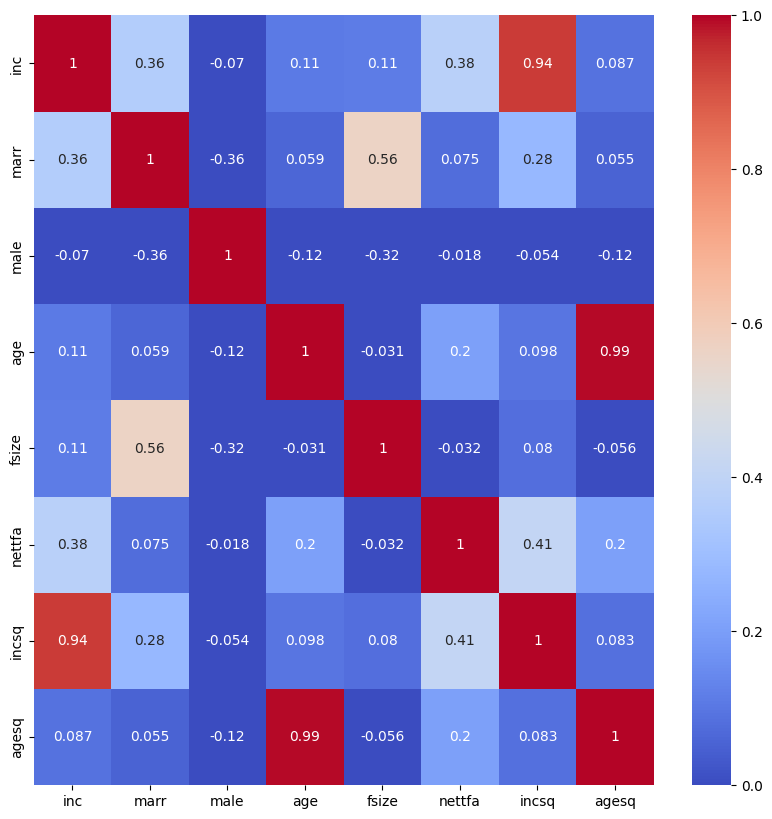

In [23]:
plt.figure(figsize=(10,10))
sns.heatmap(new.corr(), vmin=0, vmax=1, cmap='coolwarm', annot=True)

##### 8. Regardless of your answer to number 7, fit at least one of each of the following models to attempt to solve the regression problem above:
    - a multiple linear regression model
    - a k-nearest neighbors model
    - a decision tree
    - a set of bagged decision trees
    - a random forest
    - an Adaboost model
    
> As always, be sure to do a train/test split! In order to compare modeling techniques, you should use the same train-test split on each. I recommend setting a random seed here.

> You may find it helpful to set up a pipeline to try each modeling technique, but you are not required to do so!

In [26]:
X = new.drop(columns=['inc', 'incsq'])
y = new['inc']

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)

In [28]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [29]:
y_pred = model.predict(X_test)

In [40]:
print(f'R2: {model.score(X_test, y_test)}')
print(f'MSE: {mean_squared_error(y_test, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred))}')
print(f'')
print(f'')
print(f'')

R2: 0.26166694160427806
MSE: 440.21171320747317
RMSE: 20.981222872069996





##### 9. What is bootstrapping?

##### 10. What is the difference between a decision tree and a set of bagged decision trees? Be specific and precise!

##### 11. What is the difference between a set of bagged decision trees and a random forest? Be specific and precise!

##### 12. Why might a random forest be superior to a set of bagged decision trees?
> Hint: Consider the bias-variance tradeoff.

## Step 5: Evaluate the model. (Part 1: Regression Problem)

##### 13. Using RMSE, evaluate each of the models you fit on both the training and testing data.

##### 14. Based on training RMSE and testing RMSE, is there evidence of overfitting in any of your models? Which ones?

##### 15. Based on everything we've covered so far, if you had to pick just one model as your final model to use to answer the problem in front of you, which one model would you pick? Defend your choice.

##### 16. Suppose you wanted to improve the performance of your final model. Brainstorm 2-3 things that, if you had more time, you would attempt.

## Step 4: Model the data. (Part 2: Classification Problem)

Recall:
- Problem: Predict whether or not one is eligible for a 401k.
- When predicting `e401k`, you may use the entire dataframe if you wish.

##### 17. While you're allowed to use every variable in your dataframe, mention at least one disadvantage of using `p401k` in your model.

##### 18. List all modeling tactics we've learned that could be used to solve a classification problem (as of Wednesday afternoon of Week 6). For each tactic, identify whether it is or is not appropriate for solving this specific classification problem and explain why or why not.

##### 19. Regardless of your answer to number 18, fit at least one of each of the following models to attempt to solve the classification problem above:
    - a logistic regression model
    - a k-nearest neighbors model
    - a decision tree
    - a set of bagged decision trees
    - a random forest
    - an Adaboost model
    
> As always, be sure to do a train/test split! In order to compare modeling techniques, you should use the same train-test split on each. I recommend using a random seed here.

> You may find it helpful to set up a pipeline to try each modeling technique, but you are not required to do so!

## Step 5: Evaluate the model. (Part 2: Classfication Problem)

##### 20. Suppose our "positive" class is that someone is eligible for a 401(k). What are our false positives? What are our false negatives?

##### 21. In this specific case, would we rather minimize false positives or minimize false negatives? Defend your choice.

##### 22. Suppose we wanted to optimize for the answer you provided in problem 21. Which metric would we optimize in this case?

##### 23. Suppose that instead of optimizing for the metric in problem 21, we wanted to balance our false positives and false negatives using `f1-score`. Why might [f1-score](https://en.wikipedia.org/wiki/F1_score) be an appropriate metric to use here?

##### 24. Using f1-score, evaluate each of the models you fit on both the training and testing data.

##### 25. Based on training f1-score and testing f1-score, is there evidence of overfitting in any of your models? Which ones?

##### 26. Based on everything we've covered so far, if you had to pick just one model as your final model to use to answer the problem in front of you, which one model would you pick? Defend your choice.

##### 27. Suppose you wanted to improve the performance of your final model. Brainstorm 2-3 things that, if you had more time, you would attempt.

## Step 6: Answer the problem.

##### BONUS: Briefly summarize your answers to the regression and classification problems. Be sure to include any limitations or hesitations in your answer.

- Regression: What features best predict one's income?
- Classification: Predict whether or not one is eligible for a 401k.